# Linear Regression: House Price Prediction
## Train manually, train with Scikit-learn, and plot the result

**Goal:** predict a house's price using only two input features:
- `area_sqft` — house area in square feet
- `bedrooms` — number of bedrooms

The target is `price_lakh`. This is a small illustrative classroom dataset, not real property-market data.


## 1. Import the libraries
We use pandas and NumPy for data and calculations, Matplotlib for the graph, and Scikit-learn for splitting and training.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.random.seed(42)


## 2. Load the dataset
The data is included in the notebook, so no separate file upload is needed.

In [2]:
data = [{'area_sqft': 900, 'bedrooms': 2, 'price_lakh': 72}, {'area_sqft': 1100, 'bedrooms': 2, 'price_lakh': 92}, {'area_sqft': 1300, 'bedrooms': 3, 'price_lakh': 118}, {'area_sqft': 1500, 'bedrooms': 3, 'price_lakh': 132}, {'area_sqft': 1700, 'bedrooms': 3, 'price_lakh': 158}, {'area_sqft': 1900, 'bedrooms': 4, 'price_lakh': 184}, {'area_sqft': 2100, 'bedrooms': 4, 'price_lakh': 198}, {'area_sqft': 2300, 'bedrooms': 4, 'price_lakh': 228}, {'area_sqft': 1250, 'bedrooms': 2, 'price_lakh': 98}, {'area_sqft': 1800, 'bedrooms': 4, 'price_lakh': 169}]
df = pd.DataFrame(data)
df

,area_sqft,bedrooms,price_lakh
0,900,2,72
1,1100,2,92
2,1300,3,118
3,1500,3,132
4,1700,3,158
5,1900,4,184
6,2100,4,198
7,2300,4,228
8,1250,2,98
9,1800,4,169


## 3. Select the two input features and target
`X` contains the two inputs. `y` contains the house price we want the model to predict.


In [3]:
features = ["area_sqft", "bedrooms"]
target = "price_lakh"

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=float)

print("Input features:", features)
print("Number of input features:", len(features))


Input features: ['area_sqft', 'bedrooms']
Number of input features: 2


## 4. Split the data
The model learns from the training rows. The test rows are kept separate and will be used to see predictions for houses the model did not train on. `random_state=42` makes the split repeatable.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 8
Testing rows: 2


## 5. Train Linear Regression manually
With two input features, the prediction equation is:

\[
\hat y = b + w_1x_1 + w_2x_2
\]

- \(x_1\) = house area
- \(x_2\) = number of bedrooms
- \(b\) = intercept
- \(w_1\), \(w_2\) = learned weights

We standardize the inputs, add a column of ones for the intercept, and use gradient descent to update the three parameters.


In [5]:
# Standardize the two features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Add a column of ones for the intercept b
X_train_design = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_design = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

# Start with b, w1 and w2 equal to zero
theta = np.zeros(X_train_design.shape[1])

learning_rate = 0.03
epochs = 20000
n = len(y_train)

# Gradient descent repeatedly updates all three parameters
for epoch in range(epochs):
    predictions = X_train_design @ theta
    errors = predictions - y_train
    gradients = (2 / n) * (X_train_design.T @ errors)
    theta = theta - learning_rate * gradients

print("Learned intercept and scaled-feature weights:", theta)


Learned intercept and scaled-feature weights: [157.375       45.08721525   0.93643228]


## 6. View predictions from the manually trained model
The table shows actual prices beside the prices predicted by the manual model.

In [6]:
manual_predictions = X_test_design @ theta

manual_results = pd.DataFrame({
    "Actual price (lakh)": y_test,
    "Predicted price (lakh)": manual_predictions
})
manual_results.round(2)


,Actual price (lakh),Predicted price (lakh)
0,98.0,108.52
1,92.0,92.40


## 7. Train Linear Regression using Scikit-learn
Scikit-learn learns the intercept and two weights from the same training data.

In [7]:
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)

sklearn_predictions = sklearn_model.predict(X_test)

print("Intercept b:", round(sklearn_model.intercept_, 3))
for feature, weight in zip(features, sklearn_model.coef_):
    print(f"Weight for {feature}: {weight:.4f}")


Intercept b: -28.478
Weight for area_sqft: 0.1074
Weight for bedrooms: 1.3455


## 8. Plot the data and the regression plane
Because the model has **two input features**, the fitted model can be shown as a 3D plane:
- horizontal axis 1: house area
- horizontal axis 2: number of bedrooms
- vertical axis: predicted house price

The dots show the observed house prices. The plane shows the prices predicted by the Scikit-learn model.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


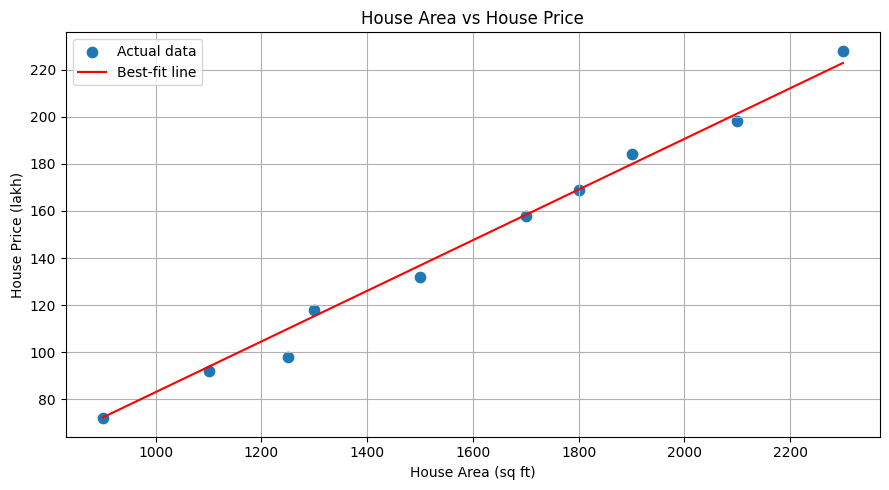

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Generate area values
area_values = np.linspace(
    df["area_sqft"].min(),
    df["area_sqft"].max(),
    100
)

# Keep bedrooms constant at their average
area_predictions = pd.DataFrame({
    "area_sqft": area_values,
    "bedrooms": df["bedrooms"].mean()
})

# Predict house prices
price_predictions = sklearn_model.predict(area_predictions[features])

# Plot actual data and best-fit line
plt.figure(figsize=(9, 5))

plt.scatter(
    df["area_sqft"],
    df["price_lakh"],
    label="Actual data",
    s=55
)

plt.plot(
    area_values,
    price_predictions,
    color="red",
    label="Best-fit line"
)

plt.xlabel("House Area (sq ft)")
plt.ylabel("House Price (lakh)")
plt.title("House Area vs House Price")
plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()

## 9. How to interpret the graph and model

**How to read the graph**
- Each dot represents one house from the dataset.
- The height of a dot represents that house's actual price.
- The flat surface is the model's predicted price for combinations of area and bedrooms.
- Dots close to the surface mean the model's predictions are close to those observed prices. Dots farther away show a larger difference.

**How to interpret the weights**
- The `area_sqft` weight tells how much the predicted price changes when area increases by one square foot, while the number of bedrooms stays the same.
- The `bedrooms` weight tells how much the predicted price changes when one bedroom is added, while the area stays the same.
- A positive weight means the predicted price increases as that feature increases. A negative weight means it decreases.

The intercept is the model's predicted price when both inputs are zero. That situation is not a realistic house, so the intercept is mainly part of the equation rather than a useful house-price interpretation.


In [9]:
area_weight = sklearn_model.coef_[0]
bedroom_weight = sklearn_model.coef_[1]

print(f"For each extra square foot, predicted price changes by {area_weight:.4f} lakh,")
print("when the number of bedrooms is held constant.")

print(f"With one additional bedroom, predicted price changes by {bedroom_weight:.4f} lakh,")
print("when the house area is held constant.")


For each extra square foot, predicted price changes by 0.1074 lakh,
when the number of bedrooms is held constant.
With one additional bedroom, predicted price changes by 1.3455 lakh,
when the house area is held constant.


## 10. Predict the price of a new house
Enter values for the same two features used during training.

In [10]:
new_house = pd.DataFrame([{
    "area_sqft": 1800,
    "bedrooms": 3
}])

new_price = sklearn_model.predict(new_house[features])[0]
print(f"Predicted house price: {new_price:.2f} lakh")


Predicted house price: 168.96 lakh


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


## Key points for students

- This model uses only **two inputs**: house area and number of bedrooms.
- The equation is `ŷ = b + w₁x₁ + w₂x₂`.
- Manual gradient descent updates the intercept and two weights.
- Scikit-learn trains the same type of model with fewer lines of code.
- The 3D graph displays actual houses and the fitted regression plane.
- Interpret each weight while keeping the other feature unchanged.

**Limitation:** the dataset is very small and illustrative. It is suitable for learning the steps, not for estimating real market prices.
